In [36]:
import sys
sys.path.append("..")

import pandas as pd
from src.limpeza import carregar_tabelas

tabelas = carregar_tabelas()
print(tabelas.keys())

dict_keys(['customers', 'geolocation', 'order_items', 'order_payments', 'order_reviews', 'orders', 'products', 'sellers', 'category_translation'])


In [37]:
tabelas["orders"]["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [38]:
pedidos = tabelas["orders"]
vendas = pedidos[pedidos["order_status"].isin(["delivered", "shipped"])]

print("Todos os pedidos:", len(pedidos))
print("Pedidos que contam como venda:", len(vendas))

Todos os pedidos: 99441
Pedidos que contam como venda: 97585


## Definição de venda

Conto como venda os pedidos com status `delivered` ou `shipped`, agrupados pela data da compra.
Motivo: Esses demonstram o resultado financeiro correlacionado com o número de vendas.
Ficam de fora: Cancelados, indisponíveis, faturados, processando, criados e aprovados. Porque não demonstram uma fonte confiável de entrada de receita no negócio.

Faturamento: soma do `payment_value` dos pedidos, ou seja, o total pago pelos clientes. Inclui frete e vouchers.

1 pedido entregue não tem registro de pagamento em `order_payments`. Ele entra na contagem de pedidos, mas com valor zero.

**Período analisado:** janeiro de 2017 a agosto de 2018.
Os meses de 2016 ficaram de fora porque têm volume muito baixo e irregular (incluindo um mês sem nenhuma venda). Setembro e outubro de 2018 ficaram de fora porque o dataset termina no início desse período, e os meses aparecem incompletos.

In [39]:
pagamentos = tabelas["order_payments"]
valor_por_pedido = pagamentos.groupby("order_id")["payment_value"].sum()

print(len(valor_por_pedido))
valor_por_pedido.head()

99440


order_id
00010242fe8c5a6d1ba2dd792cb16214     72.19
00018f77f2f0320c557190d7a144bdd3    259.83
000229ec398224ef6ca0657da4fc703e    216.87
00024acbcdf0a6daa1e931b038114c75     25.78
00042b26cf59d7ce69dfabb4e55b4fd9    218.04
Name: payment_value, dtype: float64

In [40]:
valor_por_pedido = valor_por_pedido.reset_index()

vendas = vendas.merge(valor_por_pedido, on="order_id", how="left")

print(vendas["payment_value"].isna().sum())
vendas.head()

1


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,28.62


In [41]:
vendas["order_purchase_timestamp"] = pd.to_datetime(vendas["order_purchase_timestamp"])

vendas["mes"] = vendas["order_purchase_timestamp"].dt.to_period("M")

vendas[["order_purchase_timestamp", "mes"]].head()

,order_purchase_timestamp,mes
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


In [42]:
mensal = vendas.groupby("mes").agg(
    pedidos=("order_id", "count"),
    faturamento=("payment_value", "sum")
)

mensal["ticket_medio"] = mensal["faturamento"] / mensal["pedidos"]

mensal

,pedidos,faturamento,ticket_medio
mes,,,
2016-09,2,136.23,68.115000
2016-10,273,47813.46,175.140879
2016-12,1,19.62,19.620000
2017-01,766,130510.12,170.378747
2017-02,1674,275562.12,164.612975
2017-03,2591,418978.27,161.705237
2017-04,2352,397419.10,168.970706
2017-05,3601,576106.42,159.985121
2017-06,3182,496068.51,155.898338


In [43]:
mensal_ok = mensal.loc["2017-01":"2018-08"]

mensal_ok

,pedidos,faturamento,ticket_medio
mes,,,
2017-01,766,130510.12,170.378747
2017-02,1674,275562.12,164.612975
2017-03,2591,418978.27,161.705237
2017-04,2352,397419.10,168.970706
2017-05,3601,576106.42,159.985121
2017-06,3182,496068.51,155.898338
2017-07,3928,575042.00,146.395621
2017-08,4234,652419.31,154.090531
2017-09,4188,708621.40,169.202818


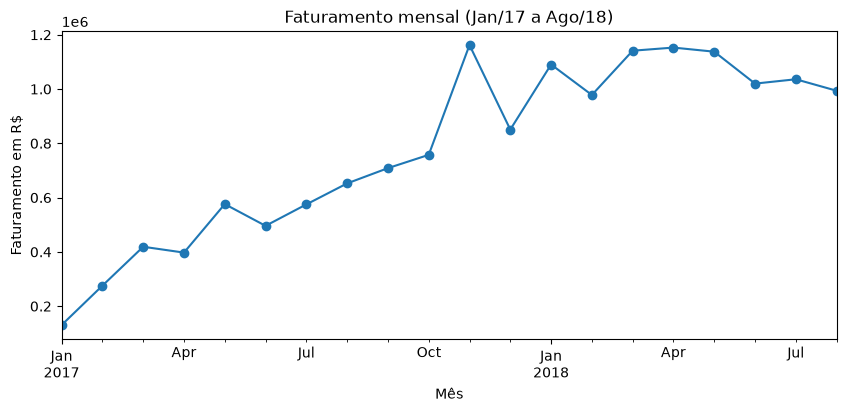

In [44]:
import matplotlib.pyplot as plt

pasta_fig = Path("../reports/figures")
pasta_fig.mkdir(parents=True, exist_ok=True)

ax = mensal_ok["faturamento"].plot(figsize=(10, 4), marker="o")
ax.set_title("Faturamento mensal (Jan/17 a Ago/18)")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento em R$")

plt.savefig(pasta_fig / "02_vendas-mensais.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
fat_2017 = mensal_ok.loc["2017-01":"2017-08", "faturamento"].sum()
fat_2018 = mensal_ok.loc["2018-01":"2018-08", "faturamento"].sum()

crescimento = fat_2018 / fat_2017 - 1

print(f"Jan-Ago 2017: R$ {fat_2017:,.0f}")
print(f"Jan-Ago 2018: R$ {fat_2018:,.0f}")
print(f"Crescimento: {crescimento:.0%}")

Jan-Ago 2017: R$ 3,522,106
Jan-Ago 2018: R$ 8,550,397
Crescimento: 143%


1. **A empresa mais que dobrou de tamanho em um ano.** De janeiro a agosto, o faturamento passou de R$ 3,5 milhões (2017) para R$ 8,6 milhões (2018), um crescimento de 143%.
2. **Em 2018, as vendas se estabilizaram num patamar alto.** Desde janeiro, o faturamento se mantém perto de R$ 1,07 milhão por mês, sem a tendência de alta de 2017. O maior pico da série foi em novembro de 2017; nossa hipótese é a Black Friday, a confirmar com dados diários. 
3. **O crescimento veio de mais pedidos, não de pedidos mais caros.** O ticket médio ficou estável, entre R$ 146,39 e R$ 170,37 por pedido, enquanto o número de pedidos cresceu. Ou seja, mais clientes comprando, cada um gastando parecido.